# AQI Prediction: EDA, Linear Regression, and Validation

Run the notebook from top to bottom. It rebuilds the cleaned dataset from `data/raw/aqi.csv`, explores data quality and relationships, then fits and evaluates a leakage-safe linear regression pipeline. The estimator predicts AQI in its original units; prediction helpers floor physically impossible negative values at zero. The held-out random split measures interpolation across sampled hourly observations; use chronological validation for future forecasting.


In [1]:
from pathlib import Path
import sys
import warnings

import joblib
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'data' / 'raw').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocess import FEATURE_COLUMNS, TARGET_COLUMN, preprocess_data
from src.features import build_features, build_preprocessor

plt.style.use('seaborn-v0_8-whitegrid')
RANDOM_STATE = 42
print('Project:', PROJECT_ROOT)


Project: c:\Users\jayku\MACHINE_LEARNING_PROJECTS\AirCast\aqi-predictor


## 1. Load and inspect the raw dataset

In [2]:
raw_path = PROJECT_ROOT / 'data' / 'raw' / 'aqi.csv'
raw = pd.read_csv(raw_path)
print(f'{raw.shape[0]:,} rows × {raw.shape[1]} columns')
display(raw.head())
display(raw.dtypes.astype(str).rename('dtype').to_frame())


52,560 rows × 16 columns


,date_ist,time_ist,location,lat,lon,temp_c,humidity,pressure_mb,windspeed_kph,condition_text,description,aqi_index,pm2_5,pm10,co,no2
0,01/01/2025,0:00,Anand Vihar,28.6469,77.316,8.1,100,995.4,2.9,Mainly clear,WMO Code 1,197,185.8,188.6,1907,56.7
1,01/01/2025,1:00,Anand Vihar,28.6469,77.316,7.7,100,994.7,3.2,Overcast,WMO Code 3,198,174.6,177.4,1669,44.8
2,01/01/2025,2:00,Anand Vihar,28.6469,77.316,7.5,100,994.3,4.5,Overcast,WMO Code 3,199,164.4,166.7,1493,34.6
3,01/01/2025,3:00,Anand Vihar,28.6469,77.316,7.8,99,994.1,6.0,Overcast,WMO Code 3,200,156.5,158.8,1401,26.7
4,01/01/2025,4:00,Anand Vihar,28.6469,77.316,7.3,100,993.8,6.8,Overcast,WMO Code 3,200,149.5,151.8,1372,20.6


,dtype
date_ist,str
time_ist,str
location,str
lat,float64
lon,float64
temp_c,float64
humidity,int64
pressure_mb,float64
windspeed_kph,float64
condition_text,str


## 2. Clean rows and derive time features
Duplicate removal and invalid target/time handling happen before analysis. Missing feature values remain available for train-fold-only imputation in the pipeline.

In [3]:
df = preprocess_data(raw_path, PROJECT_ROOT / 'data' / 'processed' / 'aqi_cleaned.csv')
print('Cleaned shape:', df.shape)
print('Duplicate rows:', df.duplicated().sum())


Rows: 52,560 -> 52,560 (duplicates/invalid target or time removed)
Feature missing values retained for fold-local imputation: 0
Saved: c:\Users\jayku\MACHINE_LEARNING_PROJECTS\AirCast\aqi-predictor\data\processed\aqi_cleaned.csv
Cleaned shape: (52560, 20)
Duplicate rows: 0


## 3. Statistical overview and missing values

In [4]:
display(df.describe(include='all').T)
missing = pd.DataFrame({'count': df.isna().sum(), 'percent': 100 * df.isna().mean()})
display(missing.sort_values('count', ascending=False))


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date_ist,52560,365,01/01/2025,144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
time_ist,52560,24,0:00,2190,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location,52560,6,Anand Vihar,8760,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lat,52560.0,NaN,NaN,NaN,28.60885,0.058927,28.5273,28.5562,28.6093,28.6469,28.7041
lon,52560.0,NaN,NaN,NaN,77.174567,0.096519,77.0494,77.1,77.1601,77.2618,77.316
temp_c,52560.0,NaN,NaN,NaN,25.024406,7.618231,5.7,19.5,26.5,30.5,43.8
humidity,52560.0,NaN,NaN,NaN,62.28594,23.454666,5.0,44.0,65.0,82.0,100.0
pressure_mb,52560.0,NaN,NaN,NaN,983.162635,6.688582,966.1,977.5,983.4,988.9,998.8
windspeed_kph,52560.0,NaN,NaN,NaN,6.56582,3.478066,0.0,4.0,6.0,8.7,27.1
condition_text,52560,11,Clear sky,30086,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,count,percent
date_ist,0,0.0
time_ist,0,0.0
location,0,0.0
lat,0,0.0
lon,0,0.0
temp_c,0,0.0
humidity,0,0.0
pressure_mb,0,0.0
windspeed_kph,0,0.0
condition_text,0,0.0


## 4. Target distribution and outlier inspection

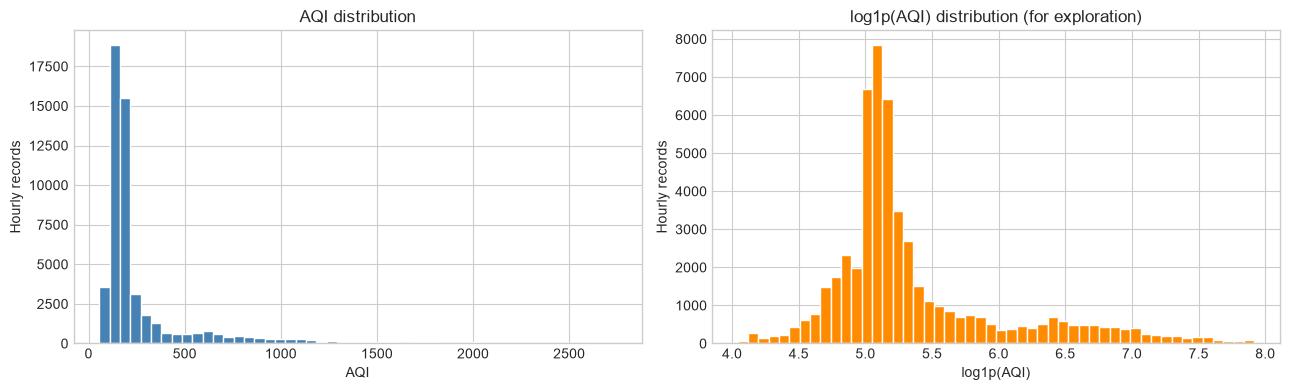

count    52560.000000
mean       287.364212
std        327.979524
min         56.000000
25%        152.000000
50%        170.000000
75%        238.000000
max       2742.000000
Name: aqi_index, dtype: float64
IQR-flagged target values: 8586


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df[TARGET_COLUMN], bins=50, color='steelblue', edgecolor='white')
axes[0].set(title='AQI distribution', xlabel='AQI', ylabel='Hourly records')
axes[1].hist(np.log1p(df[TARGET_COLUMN]), bins=50, color='darkorange', edgecolor='white')
axes[1].set(title='log1p(AQI) distribution (for exploration)', xlabel='log1p(AQI)', ylabel='Hourly records')
plt.tight_layout(); plt.show()
q1, q3 = df[TARGET_COLUMN].quantile([.25, .75]); iqr = q3-q1
print(df[TARGET_COLUMN].describe())
print('IQR-flagged target values:', int(((df[TARGET_COLUMN] < q1-1.5*iqr) | (df[TARGET_COLUMN] > q3+1.5*iqr)).sum()))


## 5. AQI by location and time

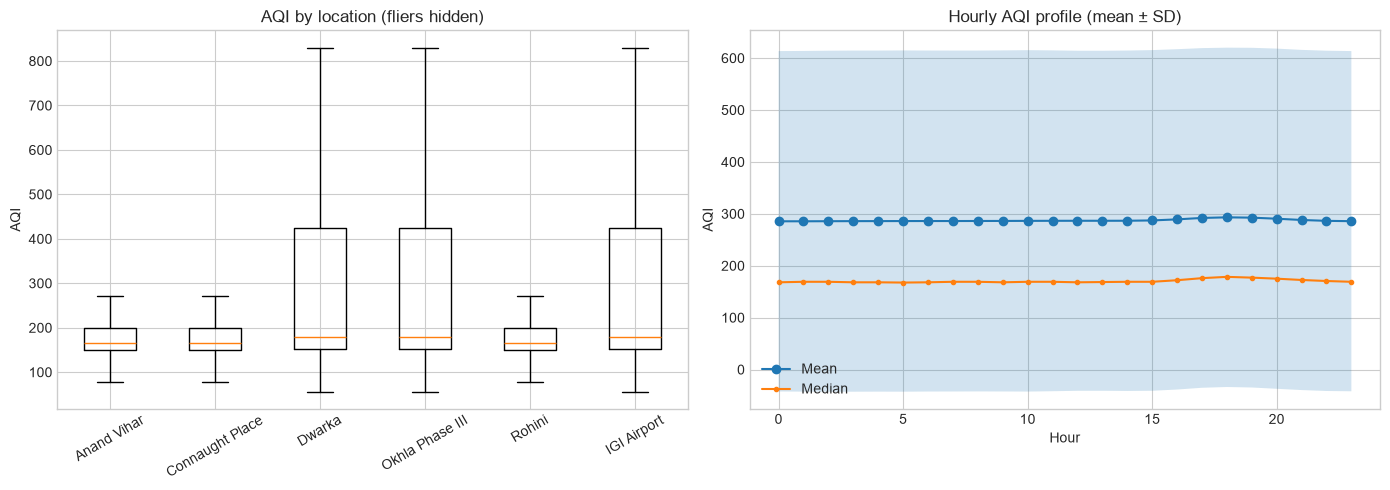

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
locations = list(df['location'].dropna().unique())
axes[0].boxplot([df.loc[df.location == p, TARGET_COLUMN] for p in locations], tick_labels=locations, showfliers=False)
axes[0].tick_params(axis='x', rotation=30); axes[0].set(title='AQI by location (fliers hidden)', ylabel='AQI')
hourly = df.groupby('hour')[TARGET_COLUMN].agg(['mean', 'median', 'std'])
axes[1].plot(hourly.index, hourly['mean'], marker='o', label='Mean')
axes[1].plot(hourly.index, hourly['median'], marker='.', label='Median')
axes[1].fill_between(hourly.index, hourly['mean']-hourly['std'], hourly['mean']+hourly['std'], alpha=.2)
axes[1].set(title='Hourly AQI profile (mean ± SD)', xlabel='Hour', ylabel='AQI'); axes[1].legend()
plt.tight_layout(); plt.show()


## 6. Pollutant relationships and correlations

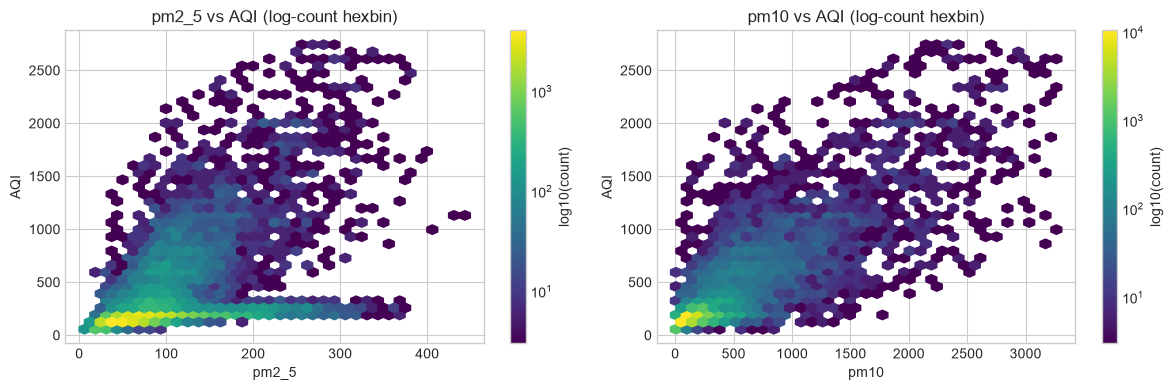

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['pm2_5', 'pm10']):
    hb = ax.hexbin(df[col], df[TARGET_COLUMN], gridsize=35, mincnt=1, bins='log', cmap='viridis')
    ax.set(title=f'{col} vs AQI (log-count hexbin)', xlabel=col, ylabel='AQI')
    fig.colorbar(hb, ax=ax, label='log10(count)')
plt.tight_layout(); plt.show()


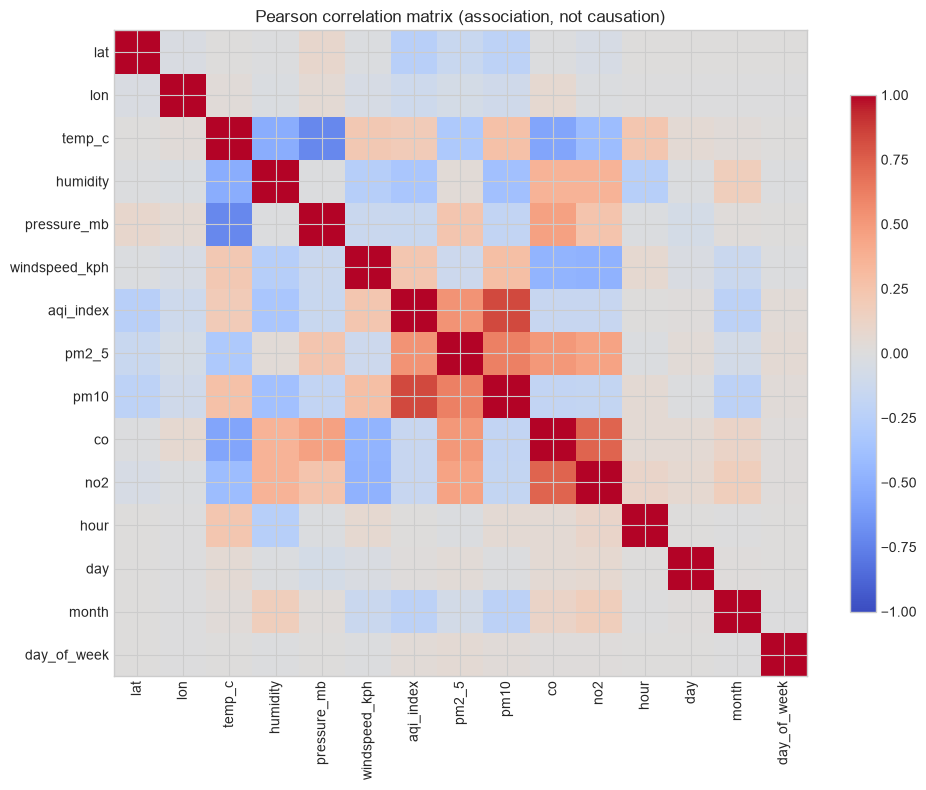

,correlation_with_aqi
pm10,0.831292
pm2_5,0.524649
humidity,-0.330126
lat,-0.248147
windspeed_kph,0.233777
month,-0.224291
temp_c,0.192220
no2,-0.155571
co,-0.150100
pressure_mb,-0.142302


In [8]:
numeric = df.select_dtypes(include='number')
corr = numeric.corr()
fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1, aspect='auto')
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr.index)), corr.index)
ax.set_title('Pearson correlation matrix (association, not causation)')
fig.colorbar(image, ax=ax, shrink=.8); plt.tight_layout(); plt.show()
display(corr[TARGET_COLUMN].drop(TARGET_COLUMN).sort_values(key=abs, ascending=False).to_frame('correlation_with_aqi'))


## 7. Train/test split and preprocessing
The split is performed before imputation, one-hot encoding, or scaling. The `ColumnTransformer` lives inside the estimator pipeline, so cross-validation refits preprocessing independently in each fold.

In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

X, y = build_features(df)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.20, random_state=RANDOM_STATE)
model = Pipeline([('preprocess', build_preprocessor()), ('regression', LinearRegression())])
model.fit(X_train, y_train)
print('Train:', X_train.shape, '| Test:', X_test.shape)


Train: (42048, 13) | Test: (10512, 13)


## 8. Held-out metrics

In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def metrics(actual, predicted):
    predicted = np.maximum(predicted, 0)
    return {'MAE': mean_absolute_error(actual, predicted),
            'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
            'R²': r2_score(actual, predicted)}

train_pred = np.maximum(model.predict(X_train), 0)
test_pred = np.maximum(model.predict(X_test), 0)
metric_table = pd.DataFrame([metrics(y_train, train_pred), metrics(y_test, test_pred)], index=['Train', 'Test'])
display(metric_table.round(3))


,MAE,RMSE,R²
Train,97.434,178.518,0.704
Test,96.683,175.973,0.711


## 9. Cross-validation and bias/variance check

In [11]:
from sklearn.model_selection import KFold, cross_validate
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_result = cross_validate(model, X_train, y_train, cv=cv,
    scoring={'r2':'r2', 'mae':'neg_mean_absolute_error', 'rmse':'neg_root_mean_squared_error'},
    return_train_score=True, n_jobs=-1)
cv_r2 = cv_result['test_r2']
print('Fold R²:', np.round(cv_r2, 4))
print(f'Mean CV R² = {cv_r2.mean():.4f} ± {cv_r2.std():.4f}')
print(f'Mean CV MAE = {-cv_result["test_mae"].mean():.2f}; RMSE = {-cv_result["test_rmse"].mean():.2f}')
gap = metric_table.loc['Train','R²'] - metric_table.loc['Test','R²']
print(f'Train − test R² gap: {gap:.4f}')
if metric_table.loc['Train','R²'] < .5 and abs(gap) < .1:
    print('Possible underfitting: both train and test fit are weak.')
elif gap > .1:
    print('Possible overfitting/high variance: train score is notably higher.')
else:
    print('Train/test scores are relatively consistent; check CV spread for stability.')


Fold R²: [0.7029 0.6938 0.7187 0.7141 0.6888]
Mean CV R² = 0.7037 ± 0.0114
Mean CV MAE = 97.49; RMSE = 178.55
Train − test R² gap: -0.0072
Train/test scores are relatively consistent; check CV spread for stability.


## 10. Prediction and residual visualizations

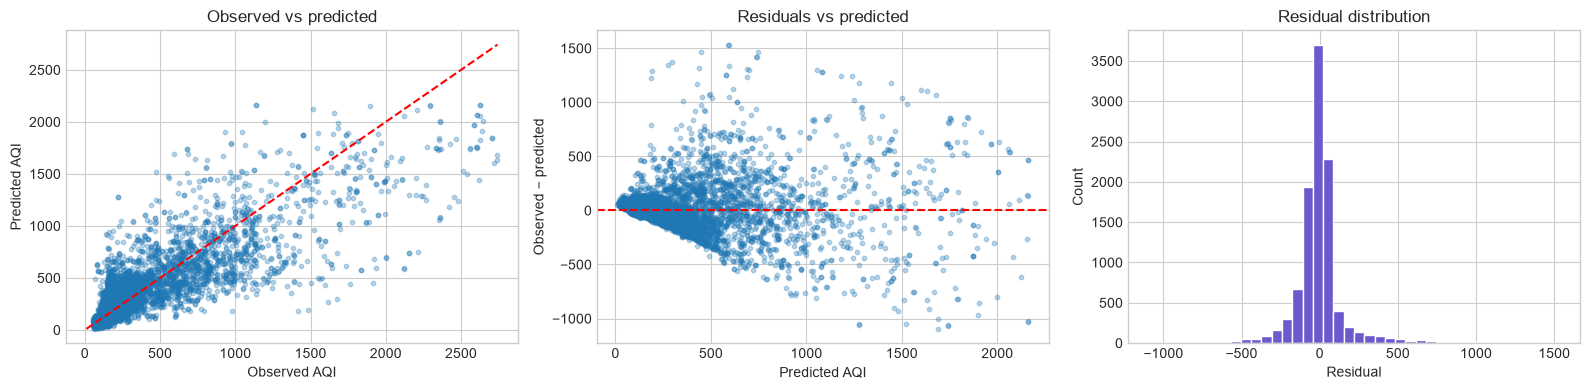

In [12]:
residuals = y_test.to_numpy() - test_pred
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(y_test, test_pred, alpha=.3, s=10)
lims = [min(y_test.min(), test_pred.min()), max(y_test.max(), test_pred.max())]
axes[0].plot(lims, lims, 'r--'); axes[0].set(title='Observed vs predicted', xlabel='Observed AQI', ylabel='Predicted AQI')
axes[1].scatter(test_pred, residuals, alpha=.3, s=10); axes[1].axhline(0, color='red', linestyle='--')
axes[1].set(title='Residuals vs predicted', xlabel='Predicted AQI', ylabel='Observed − predicted')
axes[2].hist(residuals, bins=40, color='slateblue', edgecolor='white')
axes[2].set(title='Residual distribution', xlabel='Residual', ylabel='Count')
plt.tight_layout(); plt.show()


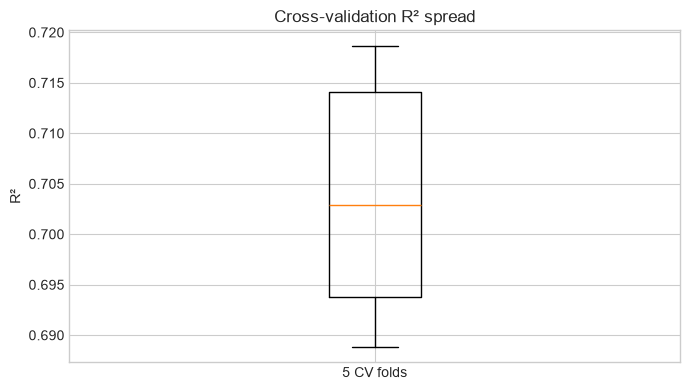

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(cv_r2, tick_labels=['5 CV folds'])
ax.set(title='Cross-validation R² spread', ylabel='R²')
plt.tight_layout(); plt.show()


## 11. Inspect linear model coefficients

,feature,coefficient_aqi,abs_coefficient
5,numeric__pm10,237.384254,237.384254
13,categorical__location_Dwarka,56.814042,56.814042
15,categorical__location_Okhla Phase III,52.989073,52.989073
14,categorical__location_IGI Airport,51.047120,51.047120
1,numeric__humidity,-28.388740,28.388740
0,numeric__temp_c,-28.157181,28.157181
4,numeric__pm2_5,26.258439,26.258439
2,numeric__pressure_mb,-22.751153,22.751153
7,numeric__no2,-16.636341,16.636341
10,numeric__month,-9.795846,9.795846


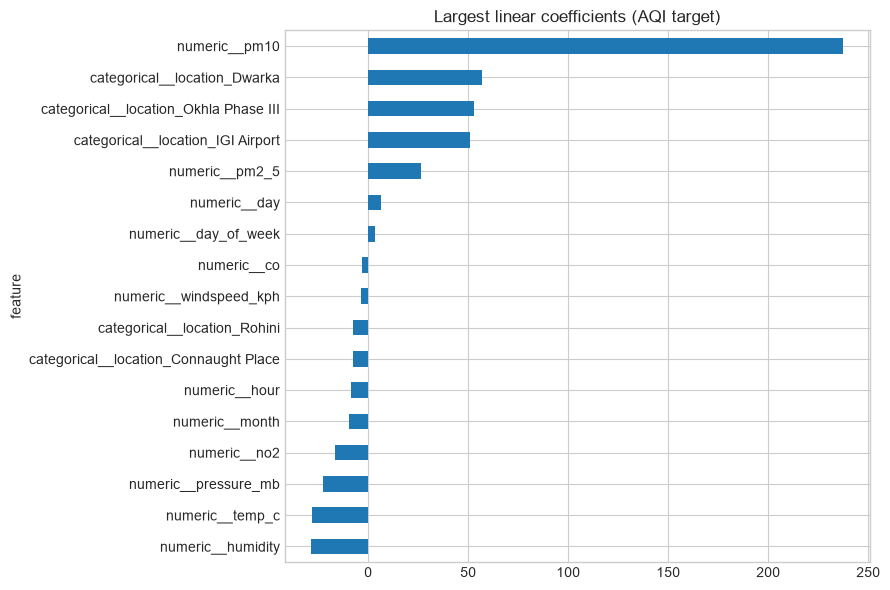

In [14]:
preprocessor = model.named_steps['preprocess']
feature_names = preprocessor.get_feature_names_out()
coefficients = model.named_steps['regression'].coef_
coef_table = pd.DataFrame({'feature': feature_names, 'coefficient_aqi': coefficients})
coef_table['abs_coefficient'] = coef_table['coefficient_aqi'].abs()
coef_table = coef_table.sort_values('abs_coefficient', ascending=False)
display(coef_table.head(20))
coef_table.head(20).sort_values('coefficient_aqi').plot.barh(x='feature', y='coefficient_aqi', figsize=(9, 6), legend=False, title='Largest linear coefficients (AQI target)')
plt.tight_layout(); plt.show()


## 12. Save model and inspect sample predictions
The saved pipeline accepts the original feature columns, including raw `location` strings; it handles encoding and scaling internally.

In [15]:
model_dir = PROJECT_ROOT / 'models'; model_dir.mkdir(exist_ok=True)
joblib.dump(model, model_dir / 'linear_regression.joblib')
examples = X_test.iloc[:10].copy()
example_predictions = np.maximum(model.predict(examples), 0)
example_table = examples[['location']].copy()
example_table['actual_aqi'] = y_test.iloc[:10].to_numpy()
example_table['predicted_aqi'] = example_predictions
example_table['absolute_error'] = abs(example_table['actual_aqi'] - example_table['predicted_aqi'])
display(example_table)
print('Saved pipeline:', model_dir / 'linear_regression.joblib')


,location,actual_aqi,predicted_aqi,absolute_error
44380,Connaught Place,161,144.075472,16.924528
20192,Connaught Place,402,395.225288,6.774712
4070,Connaught Place,199,175.175967,23.824033
26848,Dwarka,176,242.154422,66.154422
48569,Connaught Place,168,87.797638,80.202362
46411,Connaught Place,192,134.701852,57.298148
31233,IGI Airport,159,168.754641,9.754641
15016,Connaught Place,181,256.703797,75.703797
3375,Dwarka,151,176.819318,25.819318
8161,Rohini,163,173.022410,10.022410


Saved pipeline: c:\Users\jayku\MACHINE_LEARNING_PROJECTS\AirCast\aqi-predictor\models\linear_regression.joblib


## Interpretation and limitations
- MAE is the average absolute error in AQI units; RMSE penalizes large misses more; R² reports explained variance relative to predicting the mean.
- The model includes pollutant concentrations that are directly related to AQI. It predicts AQI from those measurements; it does not forecast AQI before they are measured.
- Rows are hourly and temporally adjacent. Random split and shuffled CV can be optimistic for predicting future dates. A chronological split and `TimeSeriesSplit` should be used for a forecasting deployment.
- Linear coefficients are conditional associations, not causal effects. Inspect errors by location/time before relying on individual predictions.

## 13. Compare candidate models and inspect the deployment winner
The training script compares Linear Regression, Random Forest, and XGBoost with identical fold-local preprocessing. The winner is chosen by lowest mean five-fold CV MAE, then refit on all records for deployment. Run `python src/train.py` before this section.

,model,cv_mae_mean,cv_mae_std,cv_rmse_mean,cv_r2_mean,test_mae,test_rmse,test_r2
0,Random Forest,27.918,0.425,80.710,0.939,24.579,72.992,0.950
1,XGBoost,41.531,0.476,83.717,0.935,41.338,81.658,0.938
2,Linear Regression,97.491,1.309,178.547,0.704,96.683,175.973,0.711


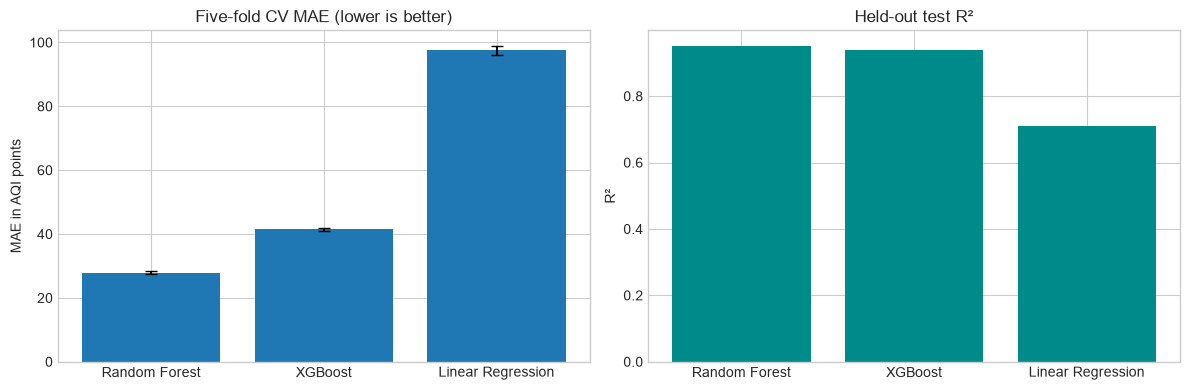

In [16]:
comparison_path = PROJECT_ROOT / 'results' / 'model_comparison.csv'
comparison = pd.read_csv(comparison_path).sort_values('cv_mae_mean')
display(comparison.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(comparison['model'], comparison['cv_mae_mean'], yerr=comparison['cv_mae_std'], capsize=4)
axes[0].set(title='Five-fold CV MAE (lower is better)', ylabel='MAE in AQI points')
axes[1].bar(comparison['model'], comparison['test_r2'], color='darkcyan')
axes[1].set(title='Held-out test R²', ylabel='R²')
plt.tight_layout(); plt.show()


In [17]:
best_report = json.loads((PROJECT_ROOT / 'results' / 'model_metrics.json').read_text(encoding='utf-8'))
best_name = best_report['best_model']
best_model = joblib.load(PROJECT_ROOT / 'models' / 'best_model.joblib')
print('Selected model:', best_name)
comparison[['model', 'cv_mae_mean', 'test_mae', 'test_rmse', 'test_r2']]


Selected model: Random Forest


,model,cv_mae_mean,test_mae,test_rmse,test_r2
0,Random Forest,27.918122,24.578541,72.992250,0.950301
1,XGBoost,41.531108,41.338036,81.658280,0.937800
2,Linear Regression,97.491337,96.683260,175.972816,0.711143


In [18]:
best_predictions = np.maximum(best_model.predict(X_test.iloc[:10]), 0)
best_examples = pd.DataFrame({'actual_aqi': y_test.iloc[:10].to_numpy(),
                              'predicted_aqi': best_predictions})
best_examples['absolute_error'] = abs(best_examples.actual_aqi - best_examples.predicted_aqi)
display(best_examples)


,actual_aqi,predicted_aqi,absolute_error
0,161,161.466592,0.466592
1,402,402.599509,0.599509
2,199,198.872371,0.127629
3,176,169.500246,6.499754
4,168,168.728118,0.728118
5,192,192.624077,0.624077
6,159,165.080104,6.080104
7,181,183.161543,2.161543
8,151,150.494792,0.505208
9,163,163.189479,0.189479
